# 15 · A 50-line PyTorch training loop: learn the Panda's gravity + Coriolis torques

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

def make_dataset(n=20000, seed=0):
    """obs = (q, qd) of the 7 arm joints (14-D); target = bias torques c(q, qd) from MuJoCo (7-D)."""
    model = mm.load("franka_emika_panda"); data = mujoco.MjData(model)
    rng = np.random.default_rng(seed)
    lo, hi = model.jnt_range[:7, 0], model.jnt_range[:7, 1]
    X, Y = np.zeros((n, 14), np.float32), np.zeros((n, 7), np.float32)
    for i in range(n):
        data.qpos[:7] = rng.uniform(lo, hi); data.qvel[:7] = rng.normal(0, 1.0, 7)
        mujoco.mj_forward(model, data)
        X[i] = np.r_[data.qpos[:7], data.qvel[:7]]; Y[i] = data.qfrc_bias[:7]
    return X, Y

class SmallPolicy(nn.Module):
    def __init__(self, d_in=14, d_out=7, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, d_out))
    def forward(self, x):
        return self.net(x)

def train(X, Y, epochs=50, lr=1e-3, batch=64, normalize=True, device="cpu", seed=0):
    torch.manual_seed(seed)
    n_val = len(X) // 10
    mx, sx = (X[n_val:].mean(0), X[n_val:].std(0) + 1e-6) if normalize else (0, 1)
    my, sy = (Y[n_val:].mean(0), Y[n_val:].std(0) + 1e-6) if normalize else (0, 1)
    Xn, Yn = torch.tensor((X - mx) / sx), torch.tensor((Y - my) / sy)
    xtr, ytr, xva, yva = Xn[n_val:].to(device), Yn[n_val:].to(device), Xn[:n_val].to(device), Yn[:n_val].to(device)
    model = SmallPolicy().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    log, step = [], 0
    for epoch in range(epochs):
        perm = torch.randperm(len(xtr), device=device)
        for i in range(0, len(xtr), batch):
            idx = perm[i:i + batch]
            loss = nn.functional.mse_loss(model(xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); step += 1
            if step % 100 == 0:
                with torch.no_grad():
                    log.append((step, loss.item(), nn.functional.mse_loss(model(xva), yva).item()))
    return model, np.array(log), (mx, sx, my, sy)

In [2]:
X, Y = make_dataset()
print("obs", X.shape, "targets", Y.shape, "torque std per joint [N·m]:", Y.std(0).round(2))

obs (20000, 14) targets (20000, 7) torque std per joint [N·m]: [2.690e+00 3.168e+01 1.261e+01 1.061e+01 1.260e+00 1.690e+00 2.000e-02]


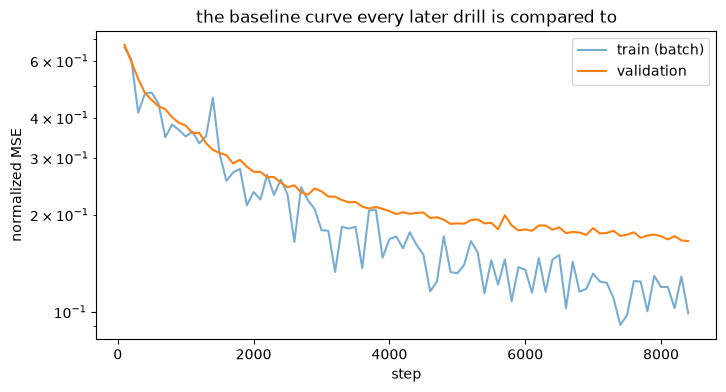

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model, log, stats = train(X, Y, epochs=30, device=device)
plt.figure(figsize=(8, 4))
plt.semilogy(log[:, 0], log[:, 1], label="train (batch)", alpha=0.6); plt.semilogy(log[:, 0], log[:, 2], label="validation")
plt.xlabel("step"); plt.ylabel("normalized MSE"); plt.legend(); plt.title("the baseline curve every later drill is compared to"); plt.show()

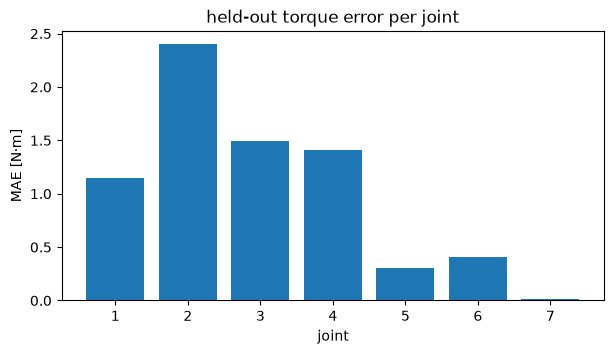

In [4]:
mx, sx, my, sy = stats
with torch.no_grad():
    pred = model(torch.tensor((X[:2000] - mx) / sx).to(device)).cpu().numpy() * sy + my
err = np.abs(pred - Y[:2000]).mean(0)
plt.figure(figsize=(7, 3.5)); plt.bar(range(1, 8), err); plt.xlabel("joint"); plt.ylabel("MAE [N·m]")
plt.title("held-out torque error per joint"); plt.show()